# 04 · Evaluation on the held-out test set

Both approaches are scored on the **33 test clips**, which neither model has seen. Both are scored through the same `ShopliftingPredictor` code that `05_predict.ipynb` uses, so these numbers describe exactly what a user gets.

**Which model is "best" is decided on the validation set, not here**, so the test numbers stay an honest estimate.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)

import pose_utils as pu

manifest = pu.load_manifest()
test = manifest[manifest.split == "test"].reset_index(drop=True)
print(f"{len(test)} test clips")
pd.crosstab(test["source"], test["label_name"])

33 test clips


label_name,normal,shoplifting
source,,
dcsass,0,4
staged,15,14


## 1. Pick the deployed model on validation

In [2]:
predictors = {a: pu.ShopliftingPredictor(a) for a in ("A", "B")}
val_scores = {a: (p.meta["val_f1"], p.meta["val_auc"]) for a, p in predictors.items()}
best = max(val_scores, key=lambda a: val_scores[a])
best_info = {"approach": best, "description": predictors[best].description,
             "val_f1": val_scores[best][0], "val_auc": val_scores[best][1],
             "chosen_by": "validation F1, then validation ROC-AUC"}
(pu.MODELS_DIR / "best_model.json").write_text(json.dumps(best_info, indent=2))
for a, p in predictors.items():
    print(f"{a}: {p.description}  (val F1 {val_scores[a][0]:.3f}, val AUC {val_scores[a][1]:.3f})")
print("Deployed:", best)

A: Approach A: hand-crafted pose features + HistGradientBoosting  (val F1 0.914, val AUC 0.873)
B: Approach B: BiGRU on pose windows (top3 of window probabilities)  (val F1 0.791, val AUC 0.701)
Deployed: A


## 2. Score the test clips

In [3]:
names = {a: p.description.split(": ", 1)[1] for a, p in predictors.items()}
for a, predictor in predictors.items():
    test[f"p_{a}"] = [predictor.predict_from_extraction(pu.load_extraction(c))["probability"] for c in test["cache_path"]]
    test[f"pred_{a}"] = (test[f"p_{a}"] >= 0.5).astype(int)
test.drop(columns=["video_path", "cache_path"]).to_csv(pu.RESULTS_DIR / "test_predictions.csv", index=False)


def metrics(y, p):
    yhat = (np.asarray(p) >= 0.5).astype(int)
    return {"n": len(y), "accuracy": accuracy_score(y, yhat),
            "precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat, zero_division=0),
            "f1": f1_score(y, yhat, zero_division=0),
            "roc_auc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan}


table = pd.DataFrame({f"{a}: {names[a]}": metrics(test["label"], test[f"p_{a}"]) for a in predictors}).T
table.to_csv(pu.RESULTS_DIR / "test_metrics.csv")
table.round(3)

,n,accuracy,precision,recall,f1,roc_auc
A: hand-crafted pose features + HistGradientBoosting,33.0,0.848,0.882,0.833,0.857,0.944
B: BiGRU on pose windows (top3 of window probabilities),33.0,0.697,0.682,0.833,0.750,0.900


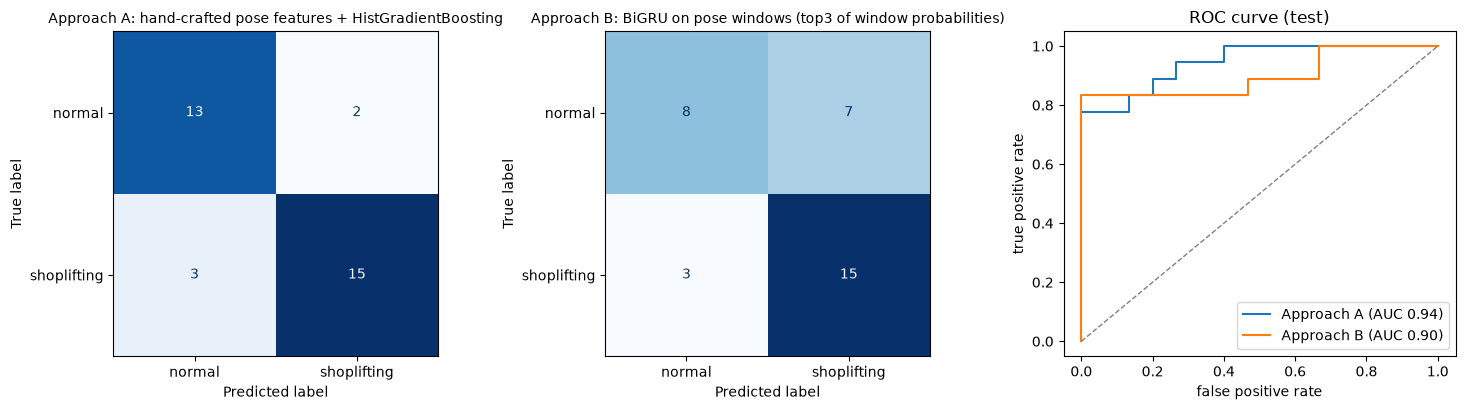

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, a in zip(axes[:2], predictors):
    cm = confusion_matrix(test["label"], test[f"pred_{a}"], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["normal", "shoplifting"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Approach {a}: {names[a]}", fontsize=10)
for a in predictors:
    fpr, tpr, _ = roc_curve(test["label"], test[f"p_{a}"])
    axes[2].plot(fpr, tpr, label=f"Approach {a} (AUC {roc_auc_score(test['label'], test[f'p_{a}']):.2f})")
axes[2].plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
axes[2].set(title="ROC curve (test)", xlabel="false positive rate", ylabel="true positive rate")
axes[2].legend(loc="lower right")
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "04_confusion_and_roc.png", dpi=150)
plt.show()

## 3. Per-source check (the DCSASS confound)

If a model were just recognising "DCSASS-looking" clips, it would score very well on DCSASS and poorly on staged clips. Note that the DCSASS test clips are **all shoplifting**, so only accuracy/recall are meaningful there (ROC-AUC needs both classes and shows as NaN).

In [5]:
by_source = []
for a in predictors:
    for src, g in test.groupby("source"):
        by_source.append({"approach": a, "source": src, **metrics(g["label"], g[f"p_{a}"])})
by_source = pd.DataFrame(by_source)
by_source.to_csv(pu.RESULTS_DIR / "test_metrics_by_source.csv", index=False)
by_source.round(3)

,approach,source,n,accuracy,precision,recall,f1,roc_auc
0,A,dcsass,4,1.000,1.000,1.000,1.000,NaN
1,A,staged,29,0.828,0.846,0.786,0.815,0.929
2,B,dcsass,4,1.000,1.000,1.000,1.000,NaN
3,B,staged,29,0.655,0.611,0.786,0.688,0.871


## 4. Headline numbers without the easy cases

Two groups of test clips make the overall numbers look better than the model really is:
- **Empty rooms:** some staged "normal" clips show an empty room. Nobody is detected (`primary_rate = 0` in notebook 01), so every feature is 0 and the models see the same blank input for all of them. Whether they get these right says nothing about recognising behaviour.
- **DCSASS clips:** all 4 DCSASS test clips are shoplifting, and DCSASS clips look different from staged ones (section 6), so getting them right may come from recognising the source rather than the behaviour.

**The "staged, person visible" row is the fairest estimate of how well the model recognises shoplifting behaviour.**

In [6]:
quality = pd.read_csv(pu.RESULTS_DIR / "pose_quality.csv").set_index("relative_path")
test["empty_room"] = test["relative_path"].map(quality["primary_rate"]) == 0
print("Empty-room test clips:", list(test.loc[test.empty_room, "relative_path"]))
subsets = {
    "all test clips": test,
    "without empty rooms": test[~test.empty_room],
    "staged only": test[test.source == "staged"],
    "staged, person visible": test[(test.source == "staged") & ~test.empty_room],
}
headline = pd.DataFrame([{"subset": name, "approach": a, **metrics(g["label"], g[f"p_{a}"])}
                         for name, g in subsets.items() for a in predictors])
headline.to_csv(pu.RESULTS_DIR / "test_metrics_subsets.csv", index=False)
headline.round(3)

Empty-room test clips: ['videos/normal/normal-13.mp4', 'videos/normal/normal-25.mp4', 'videos/normal/normal-29.mp4']


,subset,approach,n,accuracy,precision,recall,f1,roc_auc
0,all test clips,A,33,0.848,0.882,0.833,0.857,0.944
1,all test clips,B,33,0.697,0.682,0.833,0.750,0.900
2,without empty rooms,A,30,0.833,0.882,0.833,0.857,0.931
3,without empty rooms,B,30,0.667,0.682,0.833,0.750,0.875
4,staged only,A,29,0.828,0.846,0.786,0.815,0.929
5,staged only,B,29,0.655,0.611,0.786,0.688,0.871
6,"staged, person visible",A,26,0.808,0.846,0.786,0.815,0.911
7,"staged, person visible",B,26,0.615,0.611,0.786,0.688,0.839


## 5. How certain are these numbers?

With only 33 test clips, one clip changes accuracy by 3 percentage points. Two checks:
- **Bootstrap 95% confidence intervals:** resample the 33 clips with replacement 10,000 times and recompute each metric. The middle 95% of the results is the interval.
- **McNemar's exact test** for "is A really better than B?": it looks only at clips where exactly one model is right. A p-value above 0.05 means the difference could easily be chance.

In [7]:
from scipy.stats import binomtest

rng = np.random.default_rng(pu.SEED)
y = test["label"].to_numpy()
p = {a: test[f"p_{a}"].to_numpy() for a in predictors}
boot = {k: [] for k in ["acc_A", "acc_B", "f1_A", "f1_B", "auc_A", "auc_B", "acc_A_minus_B"]}
for _ in range(10_000):
    i = rng.integers(0, len(y), len(y))
    for a in predictors:
        boot[f"acc_{a}"].append(accuracy_score(y[i], p[a][i] >= 0.5))
        boot[f"f1_{a}"].append(f1_score(y[i], p[a][i] >= 0.5, zero_division=0))
        boot[f"auc_{a}"].append(roc_auc_score(y[i], p[a][i]) if len(np.unique(y[i])) == 2 else np.nan)
    boot["acc_A_minus_B"].append(boot["acc_A"][-1] - boot["acc_B"][-1])
point = {"acc_A": accuracy_score(y, p["A"] >= 0.5), "acc_B": accuracy_score(y, p["B"] >= 0.5),
         "f1_A": f1_score(y, p["A"] >= 0.5), "f1_B": f1_score(y, p["B"] >= 0.5),
         "auc_A": roc_auc_score(y, p["A"]), "auc_B": roc_auc_score(y, p["B"])}
point["acc_A_minus_B"] = point["acc_A"] - point["acc_B"]
ci = pd.DataFrame([{"metric": k, "value": point[k], "ci_low": np.nanpercentile(v, 2.5), "ci_high": np.nanpercentile(v, 97.5)}
                   for k, v in boot.items()])
ci.to_csv(pu.RESULTS_DIR / "test_confidence_intervals.csv", index=False)

right_A, right_B = test["pred_A"] == test["label"], test["pred_B"] == test["label"]
only_A, only_B = int((right_A & ~right_B).sum()), int((~right_A & right_B).sum())
mcnemar_p = binomtest(only_A, only_A + only_B, 0.5).pvalue if only_A + only_B else 1.0
print(f"McNemar: A right & B wrong = {only_A}, B right & A wrong = {only_B}, exact p = {mcnemar_p:.3f}")
ci.round(3)

McNemar: A right & B wrong = 8, B right & A wrong = 3, exact p = 0.227


,metric,value,ci_low,ci_high
0,acc_A,0.848,0.727,0.970
1,acc_B,0.697,0.545,0.848
2,f1_A,0.857,0.703,0.968
3,f1_B,0.750,0.571,0.884
4,auc_A,0.944,0.857,0.996
5,auc_B,0.900,0.765,1.000
6,acc_A_minus_B,0.152,-0.030,0.333


## 6. Is the model recognising the dataset instead of the behaviour?

The per-source table in section 3 cannot answer this, because the DCSASS test clips are all shoplifting. Two direct checks instead:
1. **Can the pose features tell the two sources apart?** Train a classifier to predict "DCSASS or staged" from the same 127 features (5-fold cross-validation over all clips; this is a diagnostic of the data and is not used for any modelling choice). An ROC-AUC near 1 means the features carry a strong fingerprint of the source.
2. **What happens to DCSASS clips that are *normal*?** There are none in test, but there are 2 in validation.

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

features = pd.read_csv(pu.RESULTS_DIR / "clip_features.csv")
is_dcsass = (features["source"] == "dcsass").astype(int)
p_source = cross_val_predict(HistGradientBoostingClassifier(random_state=pu.SEED), features[predictors["A"].meta["feature_names"]],
                             is_dcsass, cv=StratifiedKFold(5, shuffle=True, random_state=pu.SEED), method="predict_proba")[:, 1]
print(f"Pose features predict the source dataset with ROC-AUC {roc_auc_score(is_dcsass, p_source):.3f}")

val_dcsass = manifest[(manifest.split == "validation") & (manifest.source == "dcsass")]
pd.DataFrame([{"clip": r.relative_path, "true label": r.label_name,
               **{f"P(shoplifting) {a}": predictors[a].predict_from_extraction(pu.load_extraction(r.cache_path))["probability"]
                  for a in predictors}}
              for r in val_dcsass.itertuples()]).round(3)

Pose features predict the source dataset with ROC-AUC 0.996


,clip,true label,P(shoplifting) A,P(shoplifting) B
0,videos/normal/Shoplifting015_x264.mp4,normal,0.982,0.915
1,videos/normal/Shoplifting032_x264.mp4,normal,0.444,0.983
2,videos/shoplifting/Shoplifting038_x264.mp4,shoplifting,1.000,0.989
3,videos/shoplifting/Shoplifting049_x264.mp4,shoplifting,0.999,0.967


**How to read this:** if the source AUC is close to 1 and a DCSASS *normal* clip still gets a high shoplifting probability, the models have partly learned "DCSASS-looking ⇒ shoplifting". The data cannot rule this out: 24 of the 28 DCSASS clips are shoplifting. That is why the **staged-only** numbers in section 4 are the ones to trust. More DCSASS normal footage would be needed to remove the confound.

## 7. A caveat about the validation set

The same 30 validation clips were used for three decisions: Approach B's early stopping, Approach B's aggregation method, and the choice of A vs B. Validation scores are therefore optimistic. This is not leakage, since the test clips were never used for any choice, but it means **only the test numbers are unbiased estimates**.

## 8. Misclassified clips

In [9]:
wrong = test[(test["pred_A"] != test["label"]) | (test["pred_B"] != test["label"])]
wrong[["relative_path", "source", "label_name", "p_A", "p_B"]].round(3)

,relative_path,source,label_name,p_A,p_B
5,videos/normal/normal-15.mp4,staged,normal,0.808,0.502
10,videos/normal/normal-34.mp4,staged,normal,0.035,0.728
11,videos/normal/normal-41.mp4,staged,normal,0.000,0.643
15,videos/normal/normal-84.mp4,staged,normal,0.003,0.598
16,videos/normal/normal-86.mp4,staged,normal,0.080,0.731
17,videos/normal/normal-87.mp4,staged,normal,0.018,0.755
18,videos/normal/normal-88.mp4,staged,normal,0.817,0.720
19,videos/shoplifting/shoplifting-10.mp4,staged,shoplifting,0.991,0.339
20,videos/shoplifting/shoplifting-2.mp4,staged,shoplifting,0.922,0.259
21,videos/shoplifting/shoplifting-25.mp4,staged,shoplifting,0.026,0.875


## 9. Summary

The tables above (also saved in `results/`) are the numbers for the report. The figures are in `figures/`.

In [10]:
print(f"Deployed model: Approach {best} ({names[best]}), chosen on validation F1")
for a in predictors:
    r = table.loc[f"{a}: {names[a]}"]
    c = ci.set_index("metric").loc[f"acc_{a}"]
    s = headline[(headline.subset == "staged, person visible") & (headline.approach == a)].iloc[0]
    print(f"Approach {a}: all test clips accuracy {r['accuracy']:.3f} (95% CI {c.ci_low:.2f}-{c.ci_high:.2f}), "
          f"F1 {r['f1']:.3f}, ROC-AUC {r['roc_auc']:.3f} | staged with a person visible: accuracy {s['accuracy']:.3f}, "
          f"ROC-AUC {s['roc_auc']:.3f} (n={int(s['n'])})")
print(f"A vs B: McNemar exact p = {mcnemar_p:.3f} -> "
      + ("difference is statistically significant" if mcnemar_p < 0.05 else "difference is NOT statistically significant"))

Deployed model: Approach A (hand-crafted pose features + HistGradientBoosting), chosen on validation F1
Approach A: all test clips accuracy 0.848 (95% CI 0.73-0.97), F1 0.857, ROC-AUC 0.944 | staged with a person visible: accuracy 0.808, ROC-AUC 0.911 (n=26)
Approach B: all test clips accuracy 0.697 (95% CI 0.55-0.85), F1 0.750, ROC-AUC 0.900 | staged with a person visible: accuracy 0.615, ROC-AUC 0.839 (n=26)
A vs B: McNemar exact p = 0.227 -> difference is NOT statistically significant
